# AIDA 2154 Final Project – 04 Transfer Learning Compared with the Baseline

**Data version 2** (`shared/synthetic-data/kit-cards/`), using notebook 02's frozen regions and notebook 03's baseline results.

**Question:** Does a small pretrained neural network, fine-tuned on the same region crops, classify regions and flag missing items better than notebook 03's colour-and-shape baseline? Is any gain worth the added complexity?

**Method in brief.** Both classifiers use **the same frozen regions** from notebook 02's segmentation; they differ in what they see. The baseline uses colour and shape features from each region's predicted foreground mask; here, each region is cropped from its card and classified by **MobileNetV3-Small**, a small convolutional neural network pretrained on ImageNet. Only its last block and a new six-class output layer (the five kit items and "not a kit item") are trained, with light augmentation, on the same 916 training regions the baseline used. Training settings and the stopping point are chosen on an internal hold-out of **training cards**; validation is not used for tuning. The network's region predictions then go through **the same card decision rule** as the baseline, and both are compared on validation with the measures fixed in notebook 03.

**What counts as a card-level error.** A validation card has an error if any of its item decisions is a false missing-item flag, a missed omission or an unexpected detection. Decisions for items whose expectation is unknown are not scored.

**Decision rule, fixed before any network result is seen.** The baseline goes forward to robustness testing and the single test evaluation **unless the network makes strictly fewer card-level errors on validation and is no worse on every main measure**: missing-item recall, missing-item precision, false missing-item flags, unexpected detections and completely correct cards. The baseline made one card-level error (an unexpected detection on 1 of 118 cards with all expectations known), so the network would have to get every card right, keep all 43 omissions flagged, and make no false flags or unexpected detections. Validation is used once, to make this choice.

Everything uses training and validation cards only; no test image is opened, and the test set stays untouched until the method is frozen. All cards are computer-generated, so the results describe these cards, not real kits.

In [1]:
import hashlib
import json
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from PIL import Image
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)
ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
NOT_KIT = "not_kit_item"
CLASSES = ITEMS + [NOT_KIT]
DEV_SPLITS = ["train", "validation"]                  # only development images are opened

# Seeds, recorded separately for each random step
SEEDS = {"internal_holdout_split": 2026, "augmentation": 2027, "training": 2028}

sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = pd.read_csv(KIT / "manifest.csv", keep_default_na=False, na_values=[""])
regions = pd.read_csv(OUTPUT_DIR / "regions_dev.csv", keep_default_na=False, na_values=[""])                  # notebook 02
baseline_pred = pd.read_csv(OUTPUT_DIR / "region_predictions_dev.csv", keep_default_na=False, na_values=[""])  # notebook 03
training_regions = pd.read_csv(OUTPUT_DIR / "classifier_training_regions.csv")                                 # notebook 03
baseline_settings = json.loads((OUTPUT_DIR / "classifier_settings.json").read_text())

# The regions and training rows must be the ones the baseline was built from
assert sha(OUTPUT_DIR / "regions_dev.csv") == baseline_settings["regions_dev_sha256"], "Regions differ from notebook 03's"
assert sha(OUTPUT_DIR / "classifier_training_regions.csv") == baseline_settings["training_regions_sha256"], \
    "Training regions differ from notebook 03's"
assert len(training_regions) == baseline_settings["training_regions"] == 916
key = ["card_id", "region"]
assert baseline_pred[key].equals(regions[key]) and set(regions["split"]) == set(DEV_SPLITS), \
    "Baseline predictions must cover exactly the saved development regions, in order"

# Pretrained weights: the cached file must be the expected one
WEIGHTS = MobileNet_V3_Small_Weights.IMAGENET1K_V1
weights_file = Path(torch.hub.get_dir()) / "checkpoints" / Path(WEIGHTS.url).name
WEIGHTS_SHA256 = "047dcff4addef86ea5bc2eff13c9614dc11f47ab1160d0a71a25e7db994f4e1f"
assert weights_file.exists(), f"Pretrained weights not found at {weights_file}; see the README for the download step"
assert sha(weights_file) == WEIGHTS_SHA256, "The cached pretrained weights are not the expected file"

# CPU only, deterministic algorithms, fixed thread count, so reruns give the same numbers
torch.use_deterministic_algorithms(True)
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
versions = {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "pillow": Image.__version__}
print(f"Data version {DATA_VERSION}; {len(regions):,} development regions "
      f"({regions['split'].value_counts().to_dict()}); 916 training regions from notebook 03")
print(f"Pretrained weights: {weights_file.name} (sha256 checked); device: CPU, {torch.get_num_threads()} threads")
print("Versions:", versions)
print("Seeds:", SEEDS)

Data version 2; 1,243 development regions ({'train': 921, 'validation': 322}); 916 training regions from notebook 03
Pretrained weights: mobilenet_v3_small-047dcff4.pth (sha256 checked); device: CPU, 4 threads
Versions: {'python': '3.14.7', 'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.3', 'pandas': '3.0.6', 'pillow': '12.3.0'}
Seeds: {'internal_holdout_split': 2026, 'augmentation': 2027, 'training': 2028}


## A. Region crops

Each region is cut from its card image as a **square window** centred on the region's box: the side is the longer box side plus a 6-pixel margin on each side, so the item's shape is not stretched. Where the window runs past the card edge, the edge pixels are repeated. Each crop is resized to 224 × 224 pixels and normalised with ImageNet's channel means and standard deviations, as the pretrained network expects.

The crops come from the **original card image**, not from notebook 03's predicted foreground mask, so the network sees the item, a little surrounding paper and any noise or blur, as a person would. Only training and validation cards are opened.

**Reference labels** are notebook 03's: a kit-item region is labelled with its item, and a background or unmatched region as "not a kit item". Validation regions without a single reference keep a blank label and still pass through the card decisions.

**Internal hold-out.** About 20% of the **training cards** (seed 2026) are held out, before any crop is augmented, to choose training settings and the stopping point. Every crop from a card stays on the same side, and both sides must contain all six classes, or the notebook stops. Validation is not part of this split.

part,internal_fit,internal_holdout,all_training
reference,,,
access_badge,147,41,188
safety_vest,139,38,177
hard_hat,136,39,175
laptop,71,17,88
phone,73,15,88
not_kit_item,165,35,200
cards,275,69,344


Crops: 1,243 regions at 224 x 224; unused training-card regions (not in notebook 03's training rule): 5


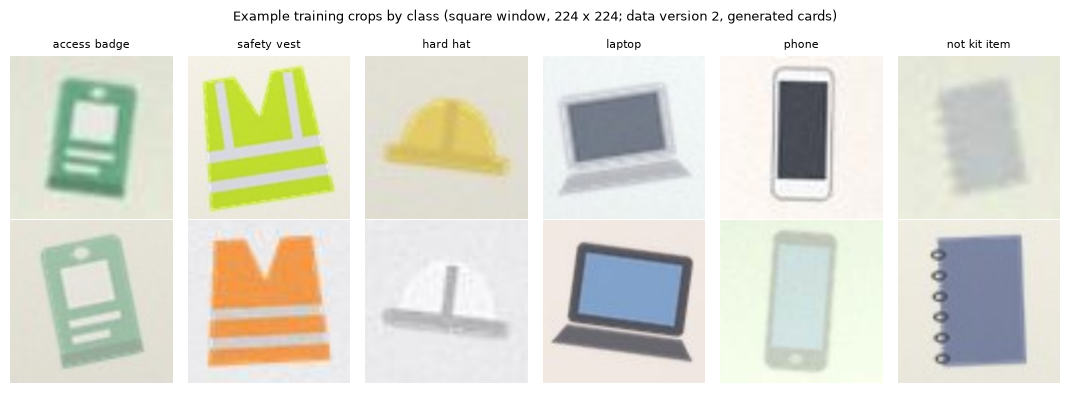

In [2]:
CROP_SIZE, MARGIN = 224, 6
files = manifest.set_index("card_id")["file_name"]
assert set(manifest.loc[manifest["card_id"].isin(regions["card_id"]), "split"]) <= set(DEV_SPLITS)


def square_crop(image, x0, y0, x1, y1):
    # Square window around the box (longer side + margin); edge pixels repeated past the card border
    side = max(x1 - x0, y1 - y0) + 2 * MARGIN                   # one integer side, so the window is always square
    left = (x0 + x1 - side) // 2
    top = (y0 + y1 - side) // 2
    right, bottom = left + side, top + side
    h, w = image.shape[:2]
    pad = max(0, -left, -top, right - w, bottom - h)
    padded = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode="edge")
    crop = padded[top + pad:bottom + pad, left + pad:right + pad]
    assert crop.shape[:2] == (side, side), "The crop window is not square"
    return crop


# Built in saved region-row order, so crop k always belongs to row k of the regions table
# Only the current card's image is kept in memory; a card is reopened only if its rows are not together
crops = np.zeros((len(regions), CROP_SIZE, CROP_SIZE, 3), dtype=np.uint8)
current_card, image = None, None
for k, r in enumerate(regions.itertuples()):
    if r.card_id != current_card:
        current_card, image = r.card_id, np.asarray(Image.open(KIT / "images" / files[r.card_id]).convert("RGB"))
    crop = square_crop(image, r.x0, r.y0, r.x1, r.y1)
    crops[k] = np.asarray(Image.fromarray(crop).resize((CROP_SIZE, CROP_SIZE), Image.Resampling.BILINEAR))
del image

data = regions[["card_id", "split", "region", "label_group"]].copy()
data["reference"] = baseline_pred["reference"].to_numpy()
data["baseline"] = baseline_pred["predicted"].to_numpy()
train_keys = set(map(tuple, training_regions[key].to_numpy()))
data["training_region"] = [k in train_keys for k in map(tuple, data[key].to_numpy())]
assert int(data["training_region"].sum()) == 916 and (data.loc[data["training_region"], "split"] == "train").all()
labelled = data.loc[data["training_region"]].merge(training_regions, on=key, suffixes=("", "_03"))
assert (labelled["reference"] == labelled["reference_03"]).all(), "Training labels differ from notebook 03's"

# Internal hold-out: about 20% of training cards, split by card before any augmentation
train_cards = np.array(sorted(data.loc[data["training_region"], "card_id"].unique()))
rng = np.random.default_rng(SEEDS["internal_holdout_split"])
holdout_cards = set(rng.choice(train_cards, size=round(0.2 * len(train_cards)), replace=False))
data["part"] = np.select([data["training_region"] & data["card_id"].isin(holdout_cards), data["training_region"],
                          data["split"] == "validation"], ["internal_holdout", "internal_fit", "validation"], default="unused")
parts = data[data["part"].isin(["internal_fit", "internal_holdout"])]
assert set(parts.loc[parts["part"] == "internal_fit", "card_id"]).isdisjoint(parts.loc[parts["part"] == "internal_holdout", "card_id"])
for p in ["internal_fit", "internal_holdout"]:
    assert set(parts.loc[parts["part"] == p, "reference"]) == set(CLASSES), f"The {p} part is missing a class"

split_table = (pd.crosstab(parts["reference"], parts["part"]).reindex(CLASSES)
               .assign(all_training=lambda t: t.sum(axis=1)))
split_table.loc["cards"] = [parts.loc[parts["part"] == c, "card_id"].nunique() for c in ["internal_fit", "internal_holdout"]] \
    + [len(train_cards)]
split_table.insert(0, "data_version", DATA_VERSION)
split_table.to_csv(OUTPUT_DIR / "tl_internal_split.csv")
display(split_table.drop(columns="data_version"))
print(f"Crops: {crops.shape[0]:,} regions at {CROP_SIZE} x {CROP_SIZE}; "
      f"unused training-card regions (not in notebook 03's training rule): {int((data['part'] == 'unused').sum())}")

# Example crops: the first two training crops of each class, in saved order
fig, axes = plt.subplots(2, len(CLASSES), figsize=(1.8 * len(CLASSES), 4))
for j, cls in enumerate(CLASSES):
    idx = data.index[data["training_region"] & (data["reference"] == cls)][:2]
    for i, k in enumerate(idx):
        axes[i, j].imshow(crops[k])
        axes[i, j].axis("off")
    axes[0, j].set_title(cls.replace("_", " "), fontsize=8)
fig.suptitle("Example training crops by class (square window, 224 x 224; data version 2, generated cards)", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tl_example_crops.png", dpi=120, bbox_inches="tight")
plt.show()